--- FIRST 5 ROWS ---
   Order_ID Customer_Name     City     Product  Quantity  Price Order_Date  \
0       101  Rahul Sharma  Chennai      Laptop         1  55000 2026-01-05   
1       102    Priya Nair   Mumbai       Mouse         2    500 2026-01-06   
2       103    Amit Verma    Delhi    Keyboard         1   1200 2026-01-07   
3       104     Sneha Rao  Chennai     Monitor         1  12000 2026-08-01   
4       105     Karthik K  Unknown  Headphones         3   1500 2026-01-09   

   Total_Sales  
0        55000  
1         1000  
2         1200  
3        12000  
4         4500  

--- SUMMARY STATISTICS ---
        Order_ID  Quantity         Price           Order_Date   Total_Sales
count    8.00000  8.000000      8.000000                    8      8.000000
mean   104.50000  1.875000  15862.500000  2026-02-03 03:00:00  16637.500000
min    101.00000  1.000000    500.000000  2026-01-05 00:00:00   1000.000000
25%    102.75000  1.000000   1025.000000  2026-01-06 18:00:00   1800.000000


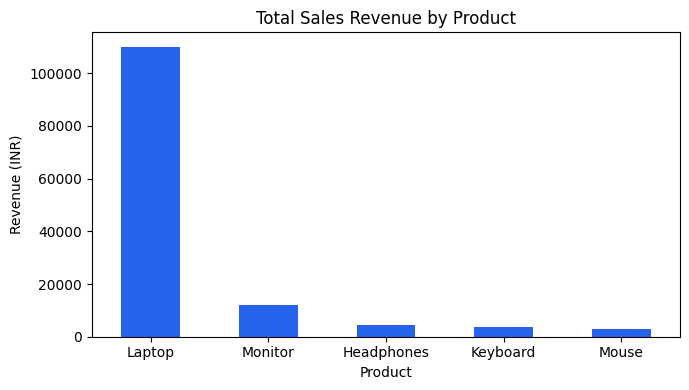

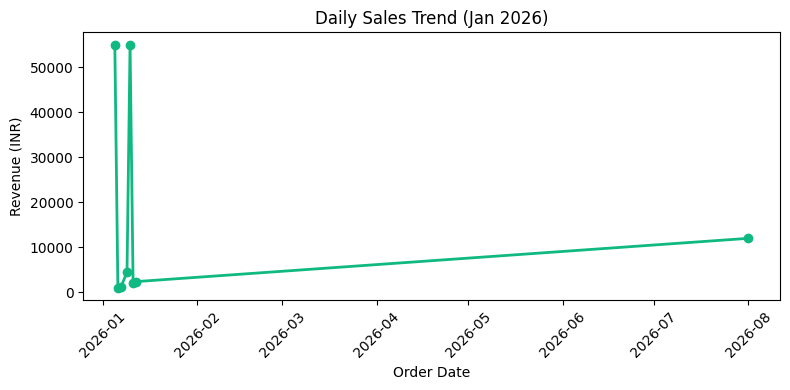

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load dataset
df = pd.read_excel('/kaggle/input/datasets/manigandan2006/sales-data/cleaned_sales_data.csv.xlsx')
df['Total_Sales'] = df['Quantity'] * df['Price']

print("--- FIRST 5 ROWS ---")
print(df.head())

print("\n--- SUMMARY STATISTICS ---")
print(df.describe())

print("\n--- REVENUE BY PRODUCT ---")
product_sales = df.groupby('Product')['Total_Sales'].sum().sort_values(ascending=False)
print(product_sales)

# 2. Bar Chart: Total Revenue by Product
plt.figure(figsize=(7, 4))
product_sales.plot(kind='bar', color='#2563eb')
plt.title('Total Sales Revenue by Product')
plt.xlabel('Product')
plt.ylabel('Revenue (INR)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('product_revenue_bar.png', dpi=150)
plt.show()

# 3. Line Chart: Daily Sales Trend
daily_sales = df.groupby('Order_Date')['Total_Sales'].sum()
plt.figure(figsize=(8, 4))
plt.plot(daily_sales.index, daily_sales.values, marker='o', color='#10b981', linewidth=2)
plt.title('Daily Sales Trend (Jan 2026)')
plt.xlabel('Order Date')
plt.ylabel('Revenue (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('daily_sales_line.png', dpi=150)
plt.show()